<a href="https://colab.research.google.com/github/Muzansama511/InteractiveNeuralNetworkTeacher/blob/main/InteractiveNNTeacher.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#@title # **Importing dependencies**
import torch
from math import ceil
import sklearn.datasets as DATASETS
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn import preprocessing
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import torch
import numpy as np
import cv2
from PIL import Image as I
from IPython.display import display,Image,Video
from tqdm import tqdm
import warnings
import shutil
import os
from sklearn.metrics import r2_score
CONFIG = {}
FINAL_SAVE={}
if os.path.exists('/content/Report'):
  shutil.rmtree('/content/Report')
if not os.path.exists('/content/Report'):
  os.mkdir('/content/Report')
if not os.path.exists('/content/Report/images'):
  os.mkdir('/content/Report/images')
if not os.path.exists('/content/Report/models'):
  os.mkdir('/content/Report/models')
if not os.path.exists('/content/Report/movies'):
  os.mkdir('/content/Report/movies')
if not os.path.exists('/content/Report/misc'):
  os.mkdir('/content/Report/misc')

In [ ]:
# This is temporary code, only used for testing the CUSTOM dataset functionality
# input_matr = np.random.rand(1000,8,8)
# input_matr[:,0,0] = 0.5
# input_matr[:,-1,-1] = -0.5
# input_matr_neg = np.random.rand(1000,8,8)
# input_matr_neg[:,0,0] = -0.5
# input_matr_neg[:,-1,-1] = 0.5
# # print(input_matr)
# input_matr = np.concatenate((input_matr,input_matr_neg),axis=0)
# print(input_matr.shape)
# output = np.concatenate((np.ones(1000),np.zeros(1000)))
# print(output.shape)
# np.save('data.npy',input_matr)
# np.save('target.npy',output)
# data = np.load('data.npy')
# data = np.sum(data,axis=1,keepdims=True)
# print(data.shape)


Description of the dataset : 
 .. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in e

<Figure size 640x480 with 0 Axes>

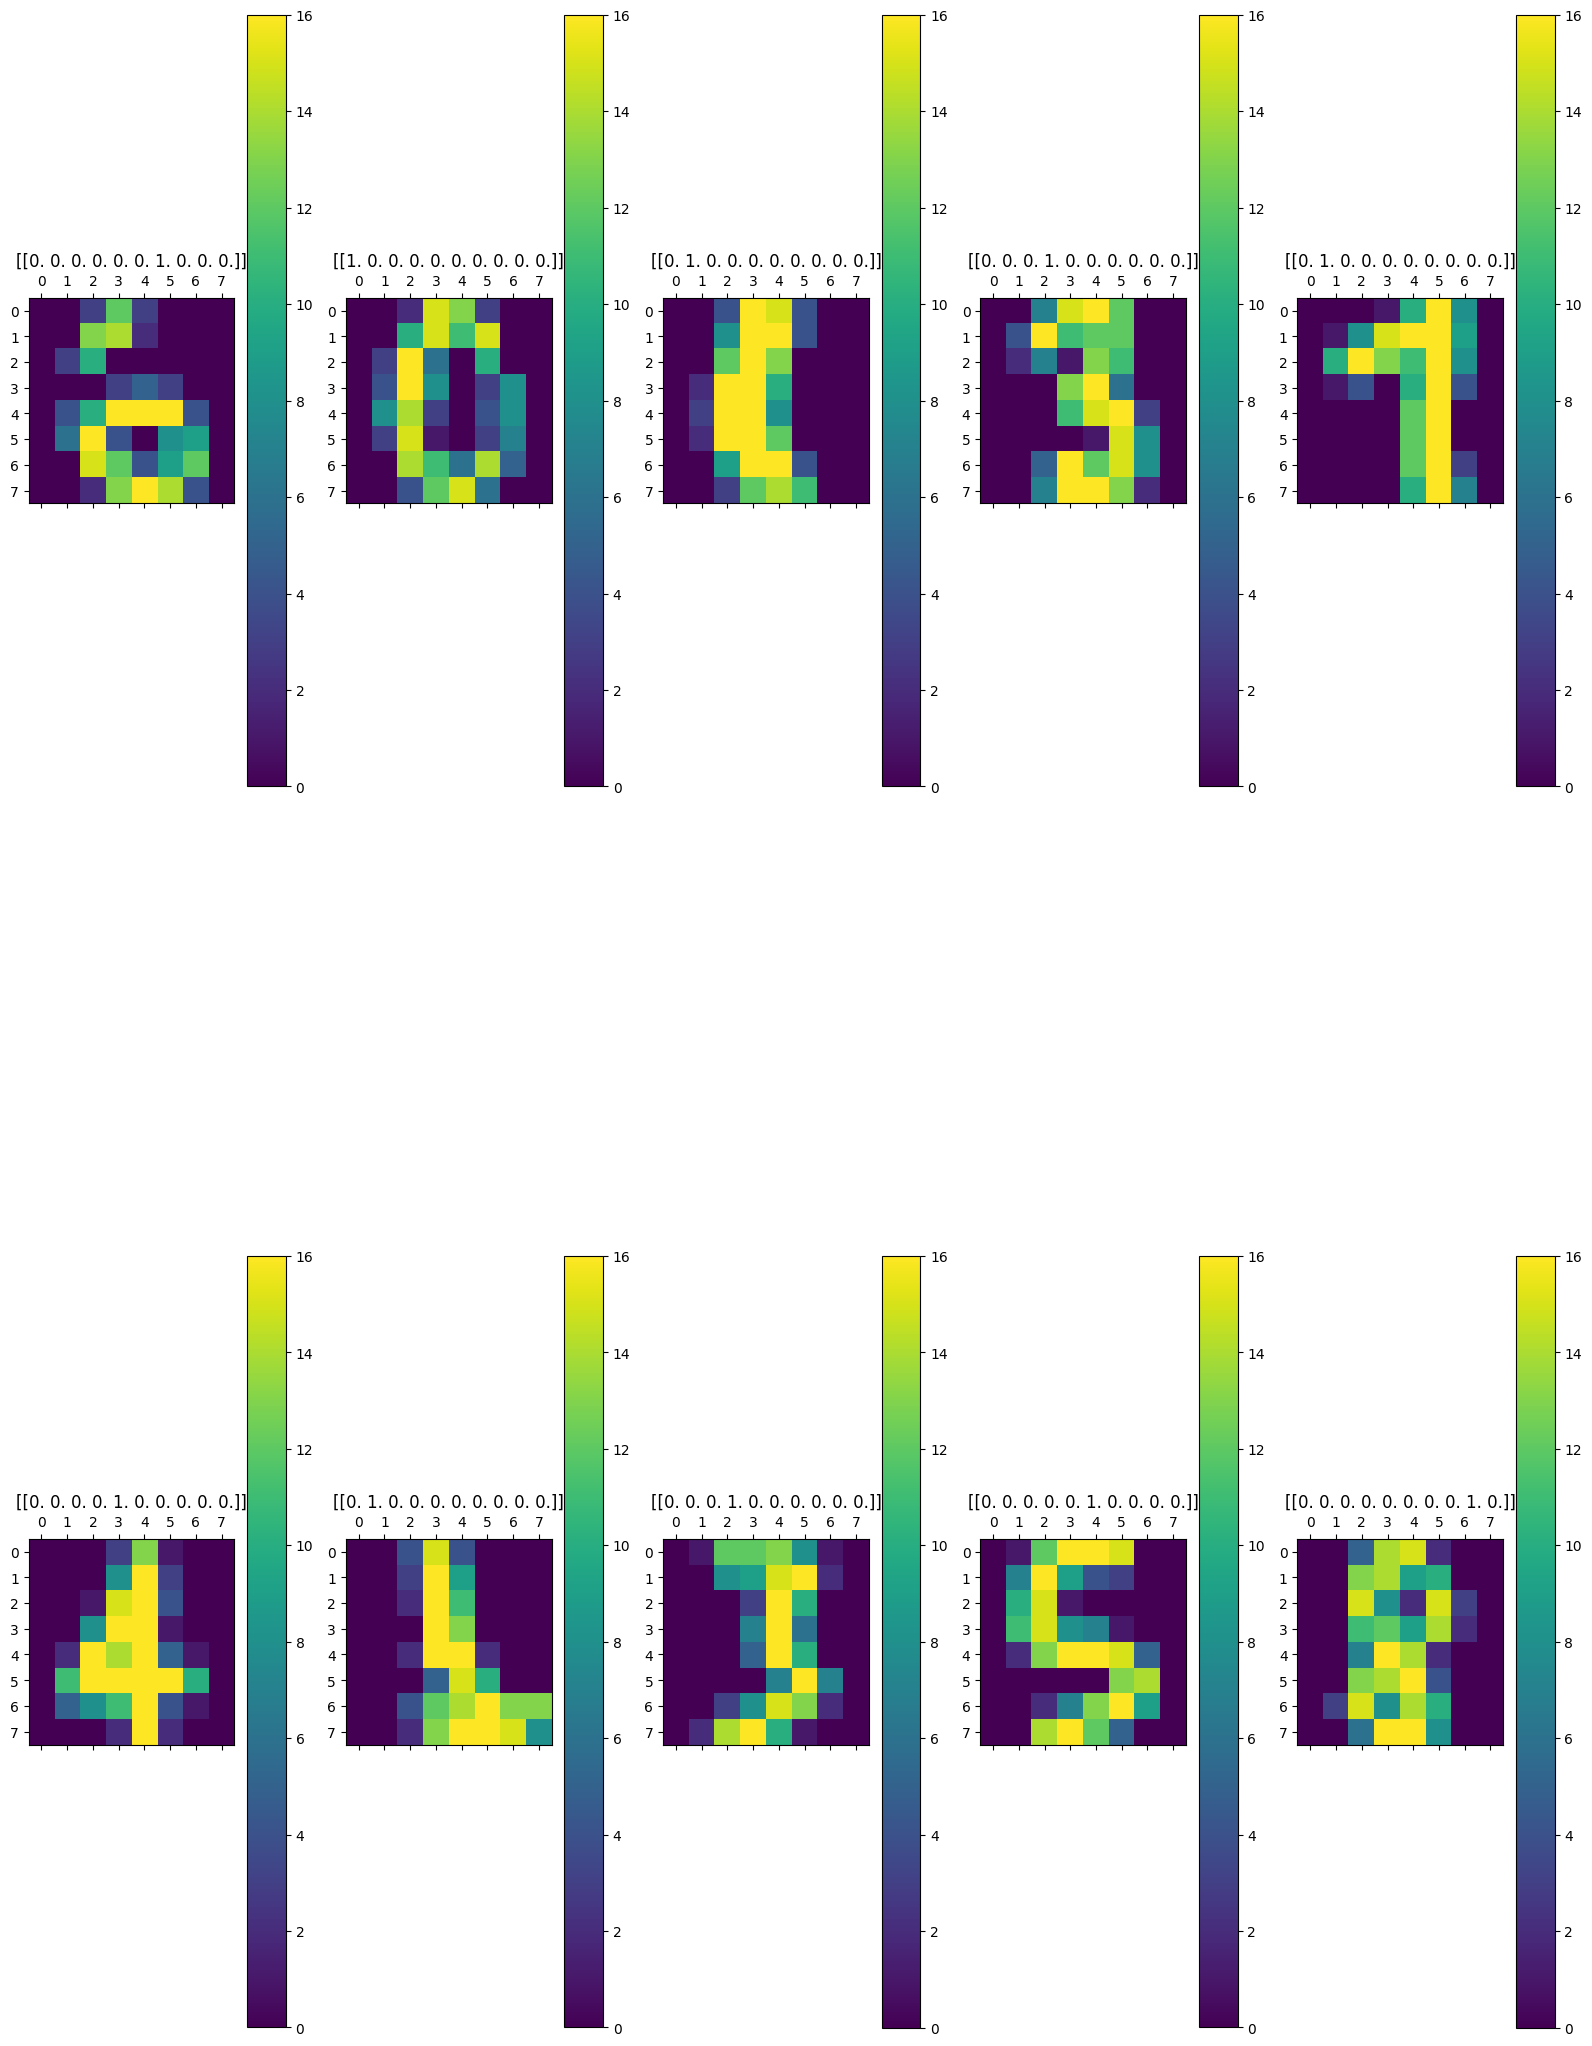

In [ ]:
#@title # **Loading the dataset and visualizing**


class DataStorage():
  def __init__(self,data,target,DESCR = ""):
    self.data = data
    self.target = target
    self.DESCR = DESCR


#@markdown * `MNIST` dataset is a collection of handwritten numbers' images of size 8x8 pixels, with the goal to predict which number is drawn. Set `task` as `Multiple Classification`, `input_dims` to 64 and `output_dims` to 10. Alternate goal is to predict whether drawn number is even or odd. For the alternate goal set the `task` as `Binary Classification` and `output_dims` to 1. <br>
#@markdown * `HOUSING` dataset is a tabular collection of 8 features about California houses with the goal to predict the price of the house in units of 100,000 Dollars. Set `task` as `Regression`, `input_dims` to 8 and `output_dims` to 1. <br>
#@markdown * `COVERTYPE` dataset is a tabular collection of 54 features about the condition of a place with the goal to predict which types of forest cover will thrive. Set `task` as `Multiple Classification`, `input_dims` to 54 and `output_dims` to 7. <br>
#@markdown * `BREAST_CANCER` dataset is a tabular collection of 30 features explaining a person's condition with the goal to predict whether the breat cancer is benign (0) or malignant (1). Set `task` as `Binary Classification`, `input_dims` to 30 and `output_dims` to 1. <br>

dataset_to_use = "MNIST" #@param ["MNIST","HOUSING","COVERTYPE","BREAST_CANCER","CUSTOM"]
task = "Multiple Classification" #@param ["Binary Classification","Multiple Classification","Regression"]
CONFIG['dataset_to_use'] = dataset_to_use
CONFIG['task'] = task
#@markdown ---

#@markdown If `CUSTOM` was chosen upload the data and target files with the numpy matrices to google colab (click on the folder icon on the left pannel and then upload file). **WARNING** this will throw an error if `CUSTOM` is chosen and no file is uploaded of the npy format.

#@markdown **NOTE:** The data file should be of shape $(B,H,W)$ or $(B,F)$ and target size should be $(B,O)$ where $B,H,W,F,O$ are integers strictly more than 0. The `input_dims` should then be set to either $H*W$ or $F$  and `output_dims` should be set to $O$.

#@markdown ---

#@markdown If `CUSTOM` is chosen provide the name of the data file and target files uploaded. Optionally can also provide the description of what the data and targets are supposed to be. **Note:** Leave unchanged if `CUSTOM` is not selected.
data_path = "data.npy" #@param {type:"string"}
target_path = "target.npy" #@param {type:"string"}
DESCR = "chemical groups encoded as one hot and attached side by side to predict the central chemical group" #@param {type:"string"}
if dataset_to_use =="MNIST":
  dataset = DATASETS.load_digits()
  dataset.data = dataset.data.reshape(-1,8,8)
  if task=='Binary Classification':
    dataset.target = dataset.target%2
elif dataset_to_use =="IRIS":
  dataset = DATASETS.load_iris()
elif dataset_to_use =="HOUSING":
  dataset = DATASETS.fetch_california_housing()
elif dataset_to_use =="COVERTYPE":
  dataset = DATASETS.fetch_covtype()
elif dataset_to_use =="BREAST_CANCER":
  dataset = DATASETS.load_breast_cancer()
elif dataset_to_use == "CUSTOM":
  data = np.load(data_path)
  target = np.load(target_path).astype(int)
  dataset = DataStorage(data,target,DESCR)

#@markdown ---

#@markdown **The input cant be scaled if it is an image**
scale_the_features = False #@param {type:"boolean"}
CONFIG['scale_the_features'] = scale_the_features

#@markdown **The output can't be scaled in a classification task**
scale_the_output = False #@param {type:"boolean"}
CONFIG['scale_the_output'] = scale_the_output

#@markdown ---

assert dataset.data.shape[0]<=dataset.target.shape[0] , (f"The number of data points should match the number of target points, received data points: {dataset.data.shape[0]} and target points: {dataset.target.shape[0]}.")

if dataset.data.shape[0]<dataset.target.shape[0]:
  warnings.warn(f"The number of data points should match the number of target points, received data points: {dataset.data.shape[0]} and target points: {dataset.target.shape[0]}. Will consider the first {dataset.data.shape[0]} target points as the target set and continue.\n")
  print(f"The number of data points should match the number of target points, received data points: {dataset.data.shape[0]} and target points: {dataset.target.shape[0]}. Will consider the first {dataset.data.shape[0]} target points as the target set and continue.\n",file=open('/content/Report/misc/warnings.txt','w'))

#@markdown The ratio of the data should be used for training: (Should be a number between 0 and 1)
train_test_split = 0.8 #@param {type:"number"}
CONFIG['train_test_split'] = train_test_split
assert 0<train_test_split and train_test_split<1, "train_test_split should be a number between 0 and 1"
if len(dataset.target.shape)==1:
  num_outs = 1
else:
  num_outs = dataset.target.shape[-1]
dataset.target = dataset.target.reshape(-1,num_outs)
if scale_the_features:
  scaler_data = preprocessing.StandardScaler()
  scaler_data.fit(dataset.data)
  dataset.data = scaler_data.transform(dataset.data)
if scale_the_output:
  scaler_target = preprocessing.StandardScaler()
  scaler_target.fit(dataset.target)
  dataset.target = scaler_target.transform(dataset.target)
dataset.target = dataset.target.reshape(-1,num_outs)
randomised_dataset = np.random.permutation(dataset.data.shape[0])
CONFIG['permut'] = randomised_dataset
np.save('/content/Report/misc/permut.npy',randomised_dataset)
print('Randowmizer for the dataset: ',randomised_dataset,file=open('/content/Report/misc/about_data.txt','w'))
print('<file name: /content/Report/misc/permut.npy>',file=open('/content/Report/misc/about_data.txt','a'))
dataset.data = dataset.data[randomised_dataset]
dataset.target = dataset.target[randomised_dataset]
if task == "Multiple Classification":
  temp_onehot_target = np.eye(int(np.max(dataset.target)+1))[dataset.target]
  dataset.target = temp_onehot_target
print('Description of the dataset : \n',dataset.DESCR,file=open('/content/Report/misc/about_data.txt','a'))
print('size of the data = ',dataset.data.shape,file=open('/content/Report/misc/about_data.txt','a'))
print('size of the target = ',dataset.target.shape,file=open('/content/Report/misc/about_data.txt','a'))
print('Sample datapoint : ',dataset.data[0],file=open('/content/Report/misc/about_data.txt','a'))
print('Sample targetpoint : ',dataset.target[0],file=open('/content/Report/misc/about_data.txt','a'))
print('<file name: /content/Report/images/sample_dataset.png>',file=open('/content/Report/misc/about_data.txt','a'))

print('Description of the dataset : \n',dataset.DESCR)
print('size of the data = ',dataset.data.shape)
print('size of the target = ',dataset.target.shape)
print('Sample datapoint : ',dataset.data[0])
print('Sample targetpoint : ',dataset.target[0])
print('<file name: /content/Report/images/sample_dataset.png>')
# print(dataset.data.shape,dataset.target.shape,file=open('/content/Report/misc/about_data.txt','w'))
plt.gray()
n=min(10,dataset.data.shape[0])
if len(dataset.data.shape)==2:
  fig = plt.figure(figsize=((int(ceil(n/5)))*(dataset.data[0].reshape(-1,dataset.data[0].shape[-1]).shape[1]),5*dataset.data[0].reshape(-1,dataset.data[0].shape[-1]).shape[0]))
elif len(dataset.data.shape)==3:
  fig = plt.figure(figsize=((int(ceil(n/5)))*(dataset.data[0].shape[1]),5*dataset.data[0].shape[0]))
for i in range(n):
  plt.subplot(int((n//5)+1),5,i+1)
  if len(dataset.data.shape)==2:
    plt.matshow(dataset.data[i].reshape(-1,dataset.data.shape[-1]),fignum=0,cmap='viridis')
  else:
    plt.matshow(dataset.data[i],fignum=0,cmap='viridis')
  plt.title(str(dataset.target[i]),fontsize=12)
  plt.colorbar()
  plt.clim(np.min(dataset.data[:n]),np.max(dataset.data[:n]))
  plt.tight_layout(pad=1)
plt.savefig('/content/Report/images/sample_dataset.png',bbox_inches='tight')
plt.show()
plt.close()


In [ ]:
#@title # **Defining the model**

if torch.cuda.is_available():
  device = 'cuda'
else:
  device = 'cpu'
CONFIG['device'] = device
#@markdown Decides whether the model should keep track of the weights as they get updated (select yes if you want to see how the weights evolve)
should_record_weights=True #@param {type:"boolean"}
CONFIG['should_record_weights'] = should_record_weights
#@markdown ---
#@markdown If the dataset being used is still MNIST please continue with input_dims = 64 (8x8 pixels)

input_dims = 64 #@param {type:"integer"}
CONFIG['input_dims'] = input_dims
#@markdown Input this in a list format. **Note:** A hidden_dim of 2 would form a layer with $2*2=4$ neurons.
hidden_dims = "5,5,5,5" #@param {type:"string"}
hidden_dims = [int(i) for i in hidden_dims.strip('[]').split(',') if i!='' ]
assert len(hidden_dims)!=0
CONFIG['hidden_dims'] = hidden_dims
hd_changed=False
#@markdown The output dimentions should be defined as 1 for simple binary classification or regression. Should match the size of target.
output_dims = 10 #@param {type:"integer"}
CONFIG['output_dims'] = output_dims
#@markdown ---

#@markdown Input the activation functions u would want to use here. Note, one activation function is used after one hidden layer output. The last hidden layer does not require any activation function as it would be decided by the type of task. Thus the length of the `activations` list should be equal to the `hidden_dims` list. Providing more activation functions than the number of hidden layers will result in the remaining activations not being used, while providing less would mean that the last activation is used for all the other remaining layers. Providing no activation functions would default every layer to be followed by `I`

#@markdown ---

#@markdown Use R for ReLU, T for TanH, S for Sigmoid, E for ELU, L for LeakyReLU, I for No activation
activations = "R" #@param {type:"string"}
activations = [str(i.strip()).upper() for i in activations.strip('[]').split(',') if i!='']
if len(activations)==0:
  activations.append('I')
CONFIG['activations'] = activations
do_batchNorm = True #@param {type:"boolean"}
CONFIG['do_batchNorm'] = do_batchNorm
#@markdown Dropout probability needs to be between 0 and 1 both inclusive.
dropout_probability = 0.2 #@param {type:"number"}
assert 0<=dropout_probability and dropout_probability<=1, "dropout_probability should be between 0 and 1 (both inclusive)"
CONFIG['dropout_probability'] = dropout_probability

class MakeModel(torch.nn.Module):
  def __init__(self,input_dims = input_dims,hidden_dims= hidden_dims,output_dims=output_dims):
    super().__init__()
    '''
    input_dims = n ; if the image is n x n in size
    hidden_dims = [a_1,a_2,...a_k] ; each hidden layer will have output size a_i*a_i
    output_dims = m ; generally keep 1 as binary classification
    '''
    self.inp = input_dims # type int
    self.hid = hidden_dims # type list of int
    self.out = output_dims #type int
    self.all = self.hid+[self.out]
    self.layers = []
    self.int_outputs = []
    self.running_mean_list = []
    self.running_std_list = []
    self.past_weights = []
    self.record=should_record_weights

    for i,h in enumerate(self.hid):
      if i==0:
        self.layers.append(torch.nn.Linear(self.inp,self.hid[i]**2))
        running_mean = torch.zeros(self.hid[i]**2,dtype=float).to(device)
        running_std = torch.ones(self.hid[i]**2,dtype=float).to(device)
        self.running_mean_list.append(running_mean)
        self.running_std_list.append(running_std)
        continue
      else:
        self.layers.append(torch.nn.Linear(self.hid[i-1]**2,self.hid[i]**2))
        running_mean = torch.zeros(self.hid[i]**2,dtype=float).to(device)
        running_std = torch.ones(self.hid[i]**2,dtype=float).to(device)
        self.running_mean_list.append(running_mean)
        self.running_std_list.append(running_std)
    self.layers.append(torch.nn.Linear(self.hid[-1]**2,self.out))

    for i,L in enumerate(self.layers):
      self.register_module(name=f'layer_{i}',module=L)
  def forward(self,x):
    device = 'cuda' if next(self.parameters()).is_cuda else 'cpu'
    self.int_outputs=[]
    # x is the image matrix
    self.int_outputs.append(x.clone().cpu().detach())
    if len(x.shape) == 3:
      x = torch.reshape(x,(-1,x.shape[-1]*x.shape[-2]))
    for i,L in enumerate(self.layers):
      x = L(x)
      if i!=len(self.layers)-1:
        # Choose an activation function from the below options. uncomment only one, comment all the others out.
        if i<len(activations):
          act_to_use = activations[i]
        else:
          act_to_use = activations[-1]
        if act_to_use == "R":
          x = torch.nn.functional.relu(x) #<--
        elif act_to_use == "T":
          x = torch.nn.functional.tanh(x) #<--
        elif act_to_use == "E":
          x = torch.nn.functional.elu(x) #<--
        elif act_to_use == "S":
          x = torch.nn.functional.sigmoid(x) #<--
        elif act_to_use == "L":
          x = torch.nn.functional.leaky_relu(x) #<--
        elif act_to_use == "I":
          x = x
        if self.training and do_batchNorm:
          torch.nn.functional.batch_norm(x,self.running_mean_list[i],self.running_std_list[i],training=self.training,momentum=0.5,eps=1e-5)
        if self.training:
          torch.nn.functional.dropout(x,p=dropout_probability)
        y = x.clone().cpu().detach().numpy()
        self.int_outputs.append(torch.tensor(y.reshape(-1,self.all[i],self.all[i])))
      else:
        if task == "Binary Classification":
          x = torch.nn.functional.sigmoid(x)
        elif task == "Multiple Classification":
          x = torch.nn.functional.softmax(x,dim=1)
        y = x.clone().cpu().detach().numpy()
        self.int_outputs.append(torch.tensor(y.reshape(-1,self.all[i])))
    return x

  def save_weights_to_list(self):
    if self.record:
      self.past_weights.append([p.clone().cpu().detach().numpy().reshape(-1,p.shape[-1]) for p in model.parameters()])




model = MakeModel()

model.to(float).to(device)
print(model)
CONFIG['model'] = model



MakeModel(
  (layer_0): Linear(in_features=64, out_features=25, bias=True)
  (layer_1): Linear(in_features=25, out_features=25, bias=True)
  (layer_2): Linear(in_features=25, out_features=25, bias=True)
  (layer_3): Linear(in_features=25, out_features=25, bias=True)
  (layer_4): Linear(in_features=25, out_features=10, bias=True)
)


In [ ]:
#@title # **Hyperparameters**
epochs = 20 #@param {type:"integer"}
learning_rate = 0.05 #@param {type:"number"}
CONFIG['epochs'] = epochs
CONFIG['learning_rate'] = learning_rate
if task =="Binary Classification":
  criterion = torch.nn.BCELoss() # Binary Cross Entropy Loss functions (Google what it means and why it is used)
elif task =="Multiple Classification":
  criterion = torch.nn.CrossEntropyLoss()
elif task == "Regression":
  criterion = torch.nn.MSELoss()
CONFIG['criterion'] = criterion
optimizer_to_use = "Adam" #@param ["Adam","SGD","RMSProp"]
if optimizer_to_use == "Adam":
  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate) # Optimizer for changing the weights after gradients are calculated, Adam also changes the learning rates for training steps
elif optimizer_to_use == "SGD":
  optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate) # Optimizer for changing the weights after gradients are calculated, Adam also changes the learning rates for training steps
elif optimizer_to_use == "RMSProp":
  optimizer = torch.optim.RMSprop(model.parameters(), lr=learning_rate) # Optimizer for changing the weights after gradients are calculated, Adam also changes the learning rates for training steps
CONFIG['optimizer'] = optimizer
def get_acc():
  # print(device)
  accuracy = 0
  correct = 0
  total = 0
  mse= 0
  model.eval()
  with torch.no_grad():
    inp = torch.tensor(dataset.data[int(len(dataset.data)*(train_test_split)+1):],dtype=float).to(device)
    y_pred_eval = model(inp)
    y_true_eval =(dataset.target[int(len(dataset.data)*(train_test_split)+1):])
    y_true_eval = torch.tensor(np.array([y_true_eval]),dtype=float).to(device)
    # print(y_pred_eval.shape)
    # print(y_true_eval.shape)
    # y_pred_eval = torch.reshape(y_pred_eval,(-1,y_pred_eval.shape[-2],y_pred_eval.shape[-1]))
    y_true_eval = torch.reshape(y_true_eval,(y_pred_eval.shape[-2],y_pred_eval.shape[-1]))
    eval_loss = criterion(y_pred_eval,y_true_eval).cpu().item()
    # print('Probability for it to be an odd number = ',y_pred.item())
    # print('The actual number = ',y_true,'\n')
    total = len(y_true_eval)
    if task=='Binary Classification':
      y_pred_bin = y_pred_eval.cpu().detach().numpy()>0.5
      correct = sum(y_pred_bin==y_true_eval.cpu().detach().numpy())
    elif task=='Multiple Classification':
      y_pred_sing = np.argmax(y_pred_eval.cpu().detach().numpy(),axis=1)
      y_true_sing = np.argmax(y_true_eval.cpu().detach().numpy(),axis=1)
      correct = sum(y_pred_sing==y_true_sing)
    # for y_pred_sing,y_true_sing in zip(y_pred_eval,y_true_eval):
    #   if task=="Binary Classification":
    #     if y_pred_sing.cpu().detach().item()>0.5 and y_true_sing.cpu().detach().item()>0.5:
    #       correct+=1
    #     elif y_pred_sing.cpu().detach().item()<0.5 and y_true_sing.cpu().detach().item()<0.5:
    #       correct+=1
    #   elif task =="Multiple Classification":
    #     if y_pred_sing.cpu().detach().numpy().argmax()==y_true_sing.cpu().detach().numpy().argmax():
    #       correct+=1
    #   total+=1
  if task == "Regression":
    # print('Average MSE Loss = ',loss/total)
    return eval_loss,r2_score(y_true_eval.cpu().detach().numpy(),y_pred_eval.cpu().detach().numpy())
  else:
    # print('Accuracy = ',correct/total)
    return eval_loss,correct/total
train_losses=[]
eval_losses=[]
train_metrices = []
eval_metrices=[]
itterations = 0
its=[]


 20%|██        | 4/20 [00:00<00:00, 35.73it/s]

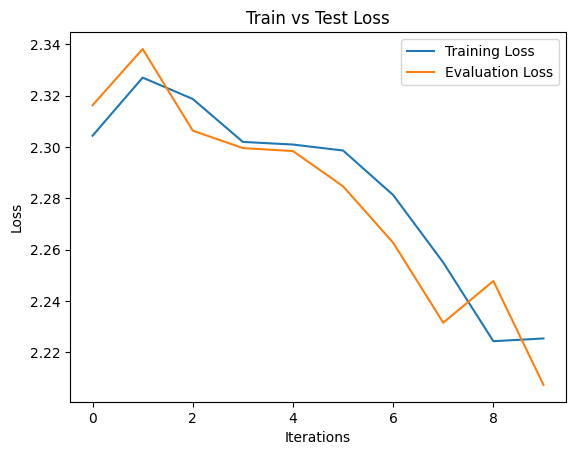

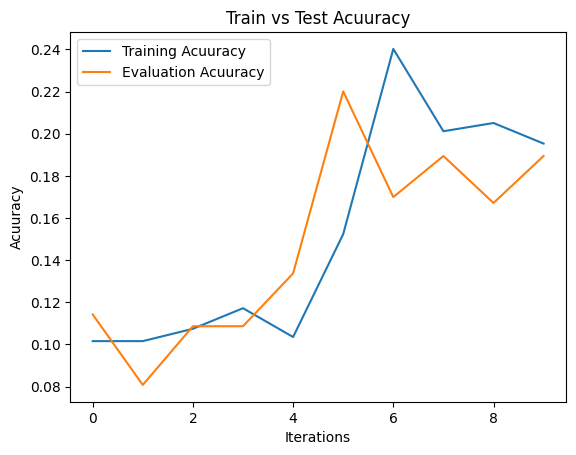

 40%|████      | 8/20 [00:01<00:01,  6.30it/s]

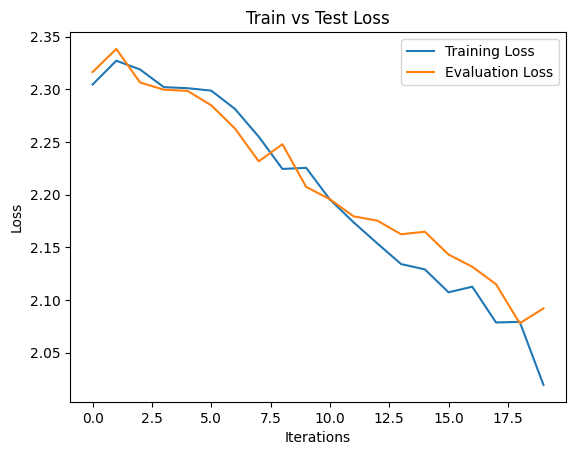

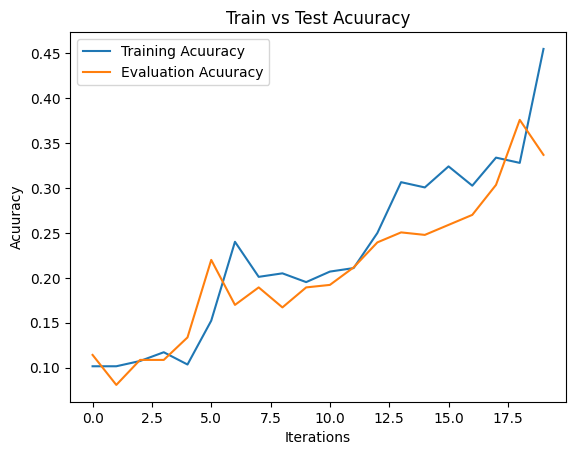

 70%|███████   | 14/20 [00:02<00:01,  5.56it/s]

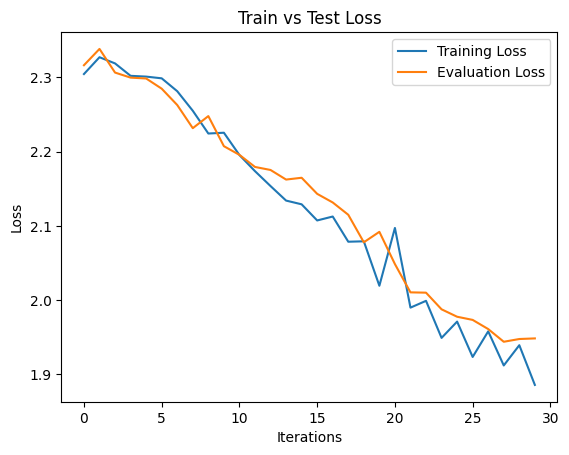

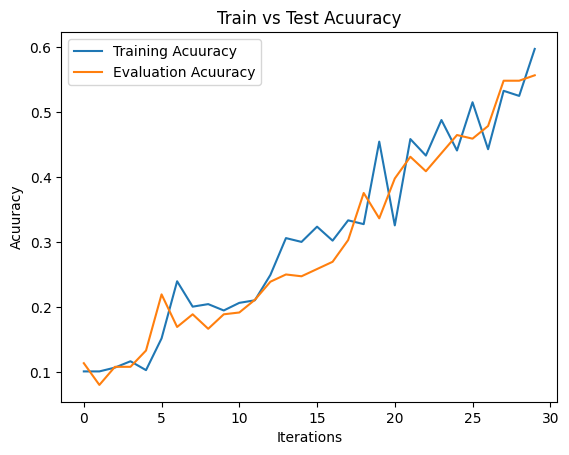

 80%|████████  | 16/20 [00:03<00:01,  3.18it/s]

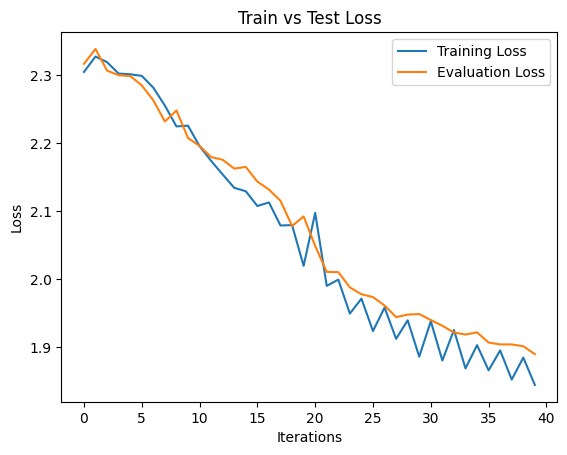

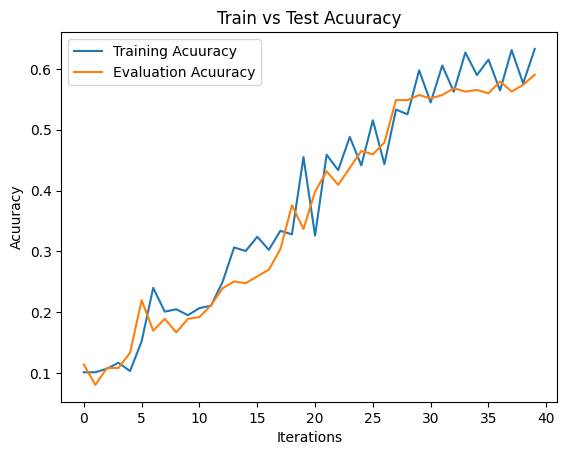

100%|██████████| 20/20 [00:04<00:00,  4.39it/s]


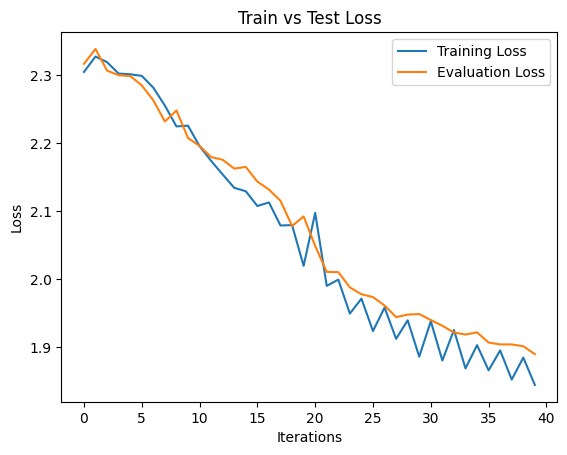

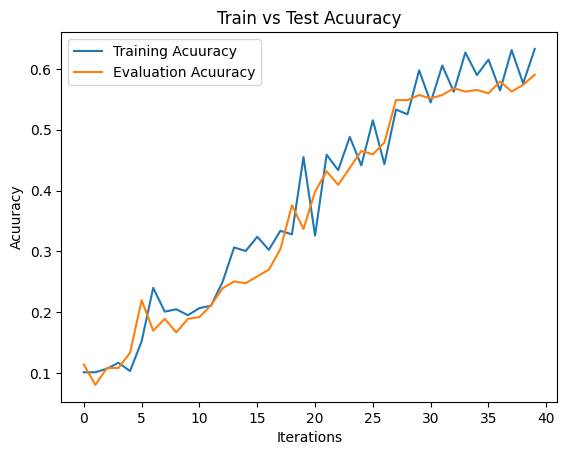

In [ ]:
#@title # **Training**

#@markdown **L1 regularization** (set to **0** if you don't want to use)
lambda_reg_l1 = 0 #@param {type:"number"}
CONFIG['lambda_reg_l1'] = lambda_reg_l1
#@markdown **L2 regularization** (set to **0** if you don't want to use)
lambda_reg_l2 = 0 #@param {type:"number"}
CONFIG['lambda_reg_l2'] = lambda_reg_l2
#@markdown ---
batch_size = 512 #@param {type:"integer"}
CONFIG['batch_size'] = batch_size
#@markdown # **If everything uptil here is set properly click `runtine` -> `run all`!**

# out = model(torch.tensor(dataset.data,dtype=float).to(device))
# print(out)
for i in tqdm(range(epochs)):
  init_loss=True
  for j in (range(int(len(dataset.data)*train_test_split)//batch_size)):
    correct=0
    r2 = 0
    model.train()
    y_true = torch.tensor(np.array([dataset.target[(j*(batch_size)):((j+1)*(batch_size))]])).to(float).to(device)
    y_true = torch.reshape(y_true,(batch_size,y_true.shape[-1])) #makes the shape into [batch_size,o] : shape of the output
    # print(torch.tensor(dataset.images[(j*(batch_size)):((j+1)*(batch_size))],dtype=float).to(device).shape)
    if (j+1)*batch_size>int(len(dataset.data)*train_test_split):
      y_pred = model(torch.tensor(dataset.data[(j*(batch_size)):int(len(dataset.data)*train_test_split)],dtype=float).to(device))
    else:
      y_pred = model(torch.tensor(dataset.data[(j*(batch_size)):((j+1)*(batch_size))],dtype=float).to(device)) # shape [1,1]
    if task!='Multiple Classification':
      loss = criterion(y_pred,y_true).to(float)
    else:
      # print(batch_size,len(y_true.argmax(dim=-1)))
      loss = criterion(y_pred,y_true.argmax(dim=-1)).to(float)
      # loss = criterion(y_pred,y_true).to(float)

    if lambda_reg_l1>0:
      l1_norm = sum([p.abs().sum() for p in model.parameters()])
      loss += lambda_reg_l1 * l1_norm
    if lambda_reg_l2>0:
      l2_norm = sum([p.pow(2).sum() for p in model.parameters()])
      loss += lambda_reg_l2 * l2_norm
    # print(loss)
    loss.backward() # calculates the gradients
    optimizer.step() # changes the weights using the calculated gradients
    optimizer.zero_grad() # makes the gradients to 0 so that the new gradients calculated are not affected by previously calculated gradients after the weights have alreayd been changed
    total = len(y_true)
    if task=='Binary Classification':
      metric = 'Acuuracy'
      y_pred_bin = y_pred.cpu().detach().numpy()>0.5
      correct = sum(y_pred_bin==y_true.cpu().detach().numpy())
    elif task=='Multiple Classification':
      metric = 'Acuuracy'
      y_pred_sing = np.argmax(y_pred.cpu().detach().numpy(),axis=1)
      y_true_sing = np.argmax(y_true.cpu().detach().numpy(),axis=1)
      correct = sum(y_pred_sing==y_true_sing)
    elif task=='Regression':
      metric = '$R^2$ Score'
      r2 = r2_score(y_true.cpu().detach().numpy(),y_pred.cpu().detach().numpy())
    train_loss = loss.item()
    eval_loss,eval_metric = get_acc()
    train_losses.append(train_loss)
    eval_losses.append(eval_loss)
    train_metrices.append(r2 if task=='Regression' else correct/total)
    eval_metrices.append(eval_metric)
    its.append(itterations)
    itterations+=1
    model.save_weights_to_list()
  if i%5==4:
    plt.plot(its,train_losses,label="Training Loss")
    plt.plot(its,eval_losses,label="Evaluation Loss")
    plt.legend()
    plt.xlabel('Iterations')
    plt.ylabel('Loss')
    plt.title('Train vs Test Loss')
    plt.show()
    plt.close()

    plt.plot(its,train_metrices,label=f"Training {metric}")
    plt.plot(its,eval_metrices,label=f"Evaluation {metric}")
    plt.legend()
    plt.xlabel('Iterations')
    plt.ylabel(f'{metric}')
    plt.title(f'Train vs Test {metric}')
    plt.show()
    plt.close()

FINAL_SAVE['train_losses'] = train_losses
FINAL_SAVE['eval_losses'] = eval_losses
FINAL_SAVE['train_metrices'] = train_metrices
FINAL_SAVE['eval_metrices'] = eval_metrices
FINAL_SAVE['its'] = its
FINAL_SAVE['model'] = model.state_dict()
FINAL_SAVE['optimizer'] = optimizer.state_dict()
plt.plot(its,train_losses,label="Training Loss")
plt.plot(its,eval_losses,label="Evaluation Loss")
plt.legend()
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Train vs Test Loss')
plt.savefig('/content/Report/images/Train_vs_Test_loss.png')
plt.show()
# plt.xticks(range(0,int(max((plt.xticks()[0])))),minor=True)
# plt.grid(which='minor',color='black')
plt.close()

plt.plot(its,train_metrices,label=f"Training {metric}")
plt.plot(its,eval_metrices,label=f"Evaluation {metric}")
plt.legend()
plt.xlabel('Iterations')
plt.ylabel(f'{metric}')
plt.title(f'Train vs Test {metric}')
if task=='Regression':
  plt.savefig(f'/content/Report/images/Train_vs_Test_r2_score.png')
else:
  plt.savefig(f'/content/Report/images/Train_vs_Test_Accuracy.png')
plt.show()
# plt.xticks(range(0,int(max((plt.xticks()[0])))),minor=True)
# plt.grid(which='minor',color='black')
# plt.show()
plt.close()

In [ ]:
#@title # **To get the accuracy/$R^2$ score**

loss,metric = get_acc()
FINAL_SAVE['metric'] = metric
FINAL_SAVE['test_loss'] = loss
if task =="Regression":
  print("r2 score is = ",metric)
else:
  print("Accuracy is = ",metric)
print('Visualization of datapoints',file=open('/content/Report/misc/sample_intermediate.txt','w'))
CONFIG['points_visualized'] = []

Accuracy is =  0.5905292479108635


In [ ]:
#@title # **t-SNE Analysis**
PERFORM_TSNE = False #@param {type:"boolean"}
PERFORM_PCA =  False #@param {type:"boolean"}
def perform_t_SNE_on_data(data,target,label):
  tsne = TSNE(n_components=2, perplexity=30, random_state=42)
  if len(data.shape) == 3:
      data = np.reshape(data,(-1,data.shape[-1]*data.shape[-2]))
  # data = dataset.data.reshape(-1,64)
  # print(len(data))
  # print(len(dataset.target))
  # print(dataset.target.shape)
  # print(np.argmax(dataset.target,axis=2))
  reduced_data = tsne.fit_transform(data)

  # Plot the results
  plt.figure(figsize=(8, 6))
  df = pd.DataFrame({
      "Dimension 1": reduced_data[:, 0],
      "Dimension 2": reduced_data[:, 1],
      "Label":  np.argmax(target,axis=-1).flatten() if len(target.shape)!=2  else target.flatten()
  })
  sns.scatterplot(
      x="Dimension 1",
      y="Dimension 2",
      hue="Label",            # Color points by label
      palette="tab10",        # Choose a color palette
      data=df,
  )
  # unique_labels = list(range(10))
  # palette = sns.color_palette("hsv", len(unique_labels))  # Use distinct colors
  # label_colors = {label: palette[i] for i, label in enumerate(unique_labels)}
  # sns.scatterplot(x=reduced_data[:, 0], y=reduced_data[:, 1])
  plt.title(f"t-SNE Visualization {label}")
  plt.xlabel("Dimension 1")
  plt.ylabel("Dimension 2")
  plt.show()

def perform_PCA_on_data(data,target,label):
  pca = PCA(n_components=2)
  if len(data.shape) == 3:
      data = np.reshape(data,(-1,data.shape[-1]*data.shape[-2]))
  # data = dataset.data.reshape(-1,64)
  # print(len(data))
  # print(len(dataset.target))
  # print(dataset.target.shape)
  # print(np.argmax(dataset.target,axis=2))
  reduced_data = pca.fit_transform(data)

  # Plot the results
  plt.figure(figsize=(8, 6))
  df = pd.DataFrame({
      "Dimension 1": reduced_data[:, 0],
      "Dimension 2": reduced_data[:, 1],
      "Label":  np.argmax(target,axis=-1).flatten() if len(target.shape)!=2  else target.flatten()
  })
  sns.scatterplot(
      x="Dimension 1",
      y="Dimension 2",
      hue="Label",            # Color points by label
      palette="tab10",        # Choose a color palette
      data=df,
  )
  # unique_labels = list(range(10))
  # palette = sns.color_palette("hsv", len(unique_labels))  # Use distinct colors
  # label_colors = {label: palette[i] for i, label in enumerate(unique_labels)}
  # sns.scatterplot(x=reduced_data[:, 0], y=reduced_data[:, 1])
  plt.title(f"PCA Visualization {label}")
  plt.xlabel("Dimension 1")
  plt.ylabel("Dimension 2")
  plt.show()

if PERFORM_TSNE:
  model.eval()
  with torch.no_grad():
    dataset_transformed = model(torch.tensor(dataset.data).to(device))
    # print(len(model.int_outputs))
    # print(model.int_outputs[-1].shape)
    for i in range(len(model.int_outputs[:-1])):
      perform_t_SNE_on_data(model.int_outputs[i].cpu().numpy(),dataset.target,label=i)

In [ ]:
#@title # **PCA Analysis**
if PERFORM_PCA:
  for i in range(len(model.int_outputs[:-1])):
    perform_PCA_on_data(model.int_outputs[i].cpu().numpy(),dataset.target,label=i)


Dataset Mean Gradients:


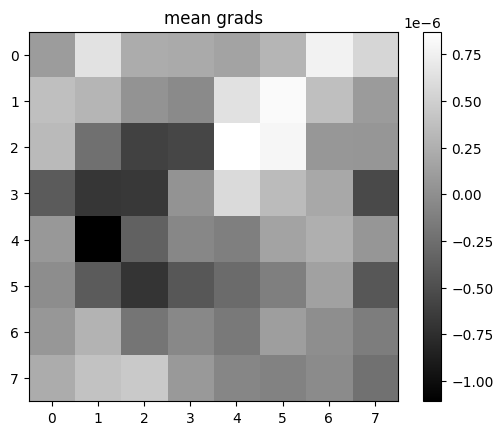

Sample Gradients:


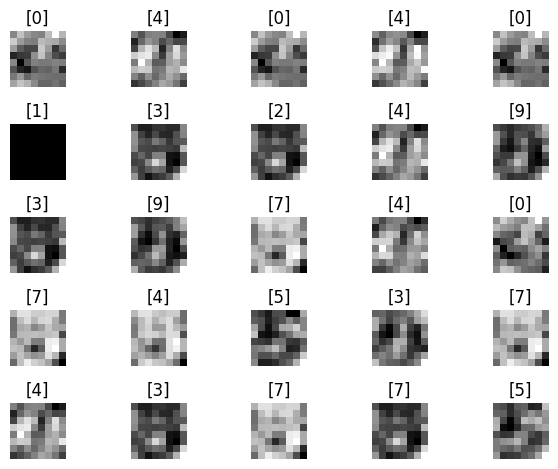

Category wise Mean Gradients:
10


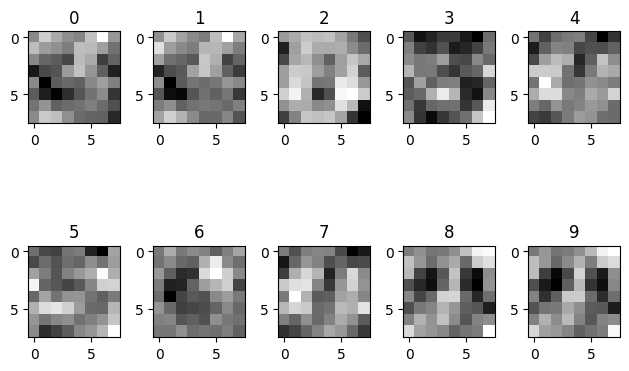

In [ ]:

#@title # **Gradients Analysis**
model.train()
model.to(float)
grad_req_data = torch.tensor(dataset.data,requires_grad=True).to(float).to(device)
grad_req_data.retain_grad()
optimizer.zero_grad()
dataset_transformed = model(grad_req_data)
# print(dataset_transformed)
# print(torch.tensor(dataset.target).argmax(dim=-1).view(len(dataset.target),-1).to(float).to(device))
if task == "Binary Classification":
  loss = criterion(dataset_transformed,torch.tensor(dataset.target).to(int).to(device))
elif task == "Multiple Classification":
  loss = criterion(dataset_transformed,torch.tensor(dataset.target).argmax(dim=-1).view(len(dataset.target)).to(int).to(device))
elif task == "Regression":
  loss = criterion(dataset_transformed,torch.tensor(dataset.target).to(float).to(device))
# loss = criterion(dataset_transformed,torch.tensor(dataset.target).argmax(dim=-1).view(len(dataset.target)).to(int).to(device))
loss.backward()
optimizer.zero_grad()

g = grad_req_data.grad
# print(g.shape)

# print(g.mean(axis=0,keepdims=True).shape)
print('Dataset Mean Gradients:')
g_m = g.mean(axis=0,keepdims=True).reshape(-1,g.shape[-1])
# plt.matshow(g_m.cpu())
plt.title('mean grads')
plt.imshow(g_m.cpu())
plt.colorbar()
plt.show()
plt.close()
print('Sample Gradients:')

n = 5
fig,ax = plt.subplots(nrows = n, ncols=n)
for i in range(n*n):
  j = np.random.choice(range(len(dataset.target)))
  # print(j)
  ax[i//n][i%n].imshow(g[j].reshape(-1,g.shape[-1]).cpu())
  if task == 'Multiple Classification':
    ax[i//n][i%n].set_title(str(dataset.target[j].argmax(axis=-1)))
  else:
    ax[i//n][i%n].set_title(str(dataset.target[j]))

  # ax[i//n][i%n].colorbar()
  ax[i//n][i%n].axis('off')
plt.tight_layout()
plt.show()
plt.close()
if task !='Regression':
  print('Category wise Mean Gradients:')
  if task =='Multiple Classification':
    num_cats = np.unique(dataset.target.argmax(axis=-1).flatten())
  else:
    num_cats = [0,1]
  print(len(num_cats))
if task=='Multiple Classification':
  fig,ax = plt.subplots(nrows = ((len(num_cats)//5)+1) if float(int(len(num_cats)/5))!=float(len(num_cats)/5) else (len(num_cats)//5) , ncols=5)
  for j,i in enumerate(num_cats):
    g_i = g[dataset.target.argmax(axis=-1).flatten()==i]
    g_i_m = g_i.mean(axis=0,keepdims=True)
    ax[j//5][j%5].set_title(f'{i}')
    ax[j//5][j%5].imshow(g_i_m[0].reshape(-1,g.shape[-1]).cpu())
  # ax[j//5][j%5].colorbar()
elif task =='Binary Classification':
  fig,ax = plt.subplots(nrows = 1 , ncols=2)
  for j,i in enumerate(num_cats):
    g_i = g[dataset.target.flatten()==i]
    g_i_m = g_i.mean(axis=0,keepdims=True)
    ax[j].set_title(f'{i}')
    ax[j].imshow(g_i_m[0].reshape(-1,g.shape[-1]).cpu())
    ax[j].axis('off')
if task !='Regression':
  plt.tight_layout()
  plt.show()
  plt.close()
# print(len(model.int_outputs))
# print(model.int_outputs[-1].shape)

# for i in range(len(model.int_outputs)):
  # perform_t_SNE_on_data(model.int_outputs[i].cpu().numpy(),dataset.target,label=i)

Index of datapoint visualized :  -2
Sample datapoint :  [[ 0.  0.  0.  2. 14.  2.  0.  0.]
 [ 0.  0.  1. 13. 15.  6.  0.  0.]
 [ 0.  0. 12. 15. 12. 11.  0.  0.]
 [ 0.  5. 16.  4. 15.  6.  0.  0.]
 [ 0. 12. 15.  8. 16. 16. 11.  0.]
 [ 0.  6. 16. 16. 16.  8.  2.  0.]
 [ 0.  0.  2.  6. 16.  0.  0.  0.]
 [ 0.  0.  0.  2. 14.  0.  0.  0.]]
Sample targetpoint :  [[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]]
predicted value =  6
actual value =  4
model intermediate matrix 0 = 
 [[[ 0.  0.  0.  2. 14.  2.  0.  0.]
  [ 0.  0.  1. 13. 15.  6.  0.  0.]
  [ 0.  0. 12. 15. 12. 11.  0.  0.]
  [ 0.  5. 16.  4. 15.  6.  0.  0.]
  [ 0. 12. 15.  8. 16. 16. 11.  0.]
  [ 0.  6. 16. 16. 16.  8.  2.  0.]
  [ 0.  0.  2.  6. 16.  0.  0.  0.]
  [ 0.  0.  0.  2. 14.  0.  0.  0.]]]


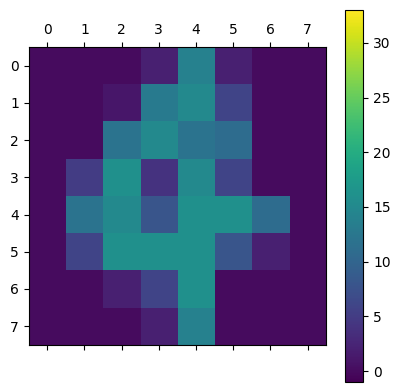

model intermediate matrix 1 = 
 [[[ 0.          0.          0.          0.          0.        ]
  [32.5600148   0.          0.         10.91079931  0.        ]
  [ 0.          0.          0.          0.          0.        ]
  [ 0.          0.          0.          0.          0.        ]
  [ 0.          0.          0.          0.          0.        ]]]


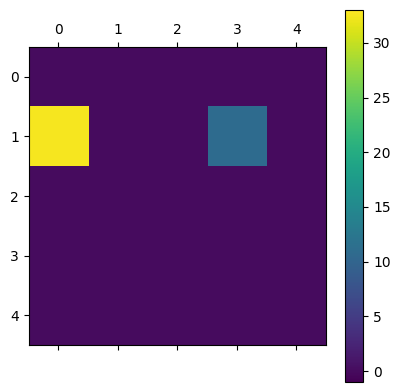

model intermediate matrix 2 = 
 [[[ 0.          2.20841359  0.          0.         14.11506771]
  [20.37969419  0.          0.          0.          0.        ]
  [ 9.694328    0.          0.          0.          0.        ]
  [ 0.          0.          0.          0.          0.        ]
  [ 0.          0.          0.         16.51884678  0.        ]]]


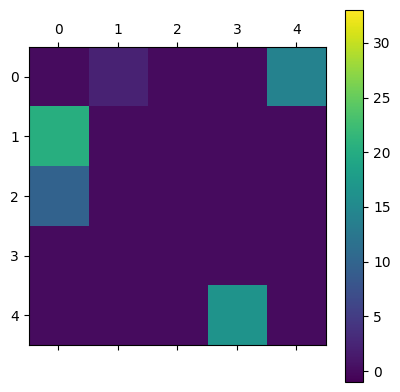

model intermediate matrix 3 = 
 [[[ 0.          0.          8.87490873  0.          0.        ]
  [ 0.          0.          0.          0.          0.        ]
  [ 0.          0.          0.          0.          0.        ]
  [27.05841582  0.          0.          0.          0.        ]
  [ 0.          0.          0.          7.9982269   0.        ]]]


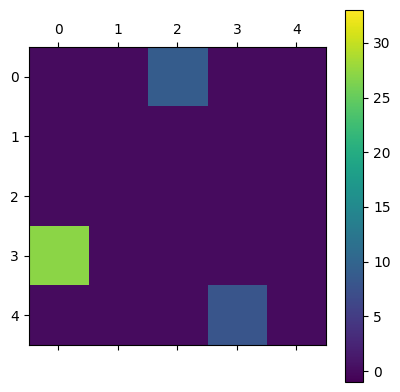

model intermediate matrix 4 = 
 [[[ 0.          0.          0.          0.          0.        ]
  [ 0.          0.          0.          0.          0.        ]
  [ 0.          0.          0.          0.          0.        ]
  [ 0.          0.          0.          7.45641761  0.        ]
  [ 2.13903934  0.         20.30432585  0.          0.        ]]]


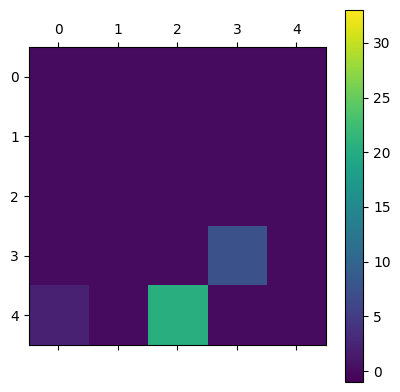

model intermediate matrix 5 = 
 [[2.47445877e-05 2.04214192e-02 6.58545385e-08 1.91170366e-15
  1.55788419e-05 9.88496961e-10 9.79538154e-01 1.24807623e-12
  3.65624601e-08 6.76900414e-18]]


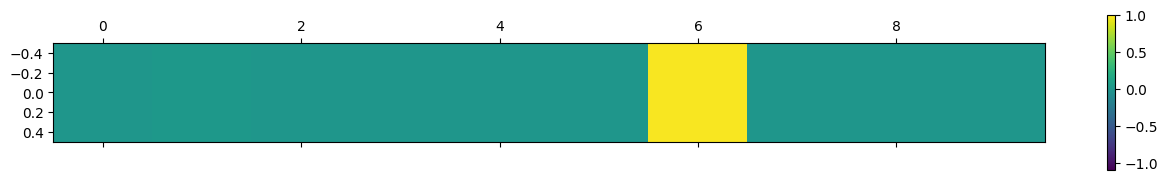

In [ ]:
#@title # **Sample for the intermediate outputs**
model.eval()
which_datapoint_to_visualize=-2 #@param {type:"integer"}

which = which_datapoint_to_visualize
CONFIG['points_visualized'].append(which)
print('Index of datapoint visualized : ',which,file=open('/content/Report/misc/sample_intermediate.txt','a'))
print('Sample datapoint : ',dataset.data[which],file=open('/content/Report/misc/sample_intermediate.txt','a'))
print('Sample targetpoint : ',dataset.target[which],file=open('/content/Report/misc/sample_intermediate.txt','a'))


print('Index of datapoint visualized : ',which)
print('Sample datapoint : ',dataset.data[which])
print('Sample targetpoint : ',dataset.target[which])
with torch.no_grad():
  y_pred = model(torch.tensor(np.array([dataset.data[which]]),dtype=float).to(device))
  y_true =(dataset.target[which])
  if task == "Binary Classification":
    print('predicted probability = ', y_pred.cpu().detach().item(),file=open('/content/Report/misc/sample_intermediate.txt','a'))
    print('actual value = ',y_true,file=open('/content/Report/misc/sample_intermediate.txt','a'))


    print('predicted probability = ', y_pred.cpu().detach().item())
    print('actual value = ',y_true)
  elif task =="Multiple Classification":
    print('predicted value = ', y_pred.cpu().detach().numpy().argmax(),file=open('/content/Report/misc/sample_intermediate.txt','a'))
    print('actual value = ',y_true.argmax(),file=open('/content/Report/misc/sample_intermediate.txt','a'))

    print('predicted value = ', y_pred.cpu().detach().numpy().argmax())
    print('actual value = ',y_true.argmax())
  elif task =="Rgeression":
    print('predicted value = ', y_pred.cpu().detach().numpy(),file=open('/content/Report/misc/sample_intermediate.txt','a'))
    print('actual value = ',y_true,file=open('/content/Report/misc/sample_intermediate.txt','a'))

    print('predicted value = ', y_pred.cpu().detach().numpy())
    print('actual value = ',y_true)
  upper_clim = int(torch.max(torch.tensor([torch.max(m) for m in model.int_outputs])).item())+1 # used to calculate the cbar upperlimit
  lower_clim = int(torch.min(torch.tensor([torch.min(m) for m in model.int_outputs])).item())-1 # used to calculate the cbar lowerlimit
  # print(upper_clim)
  for i,out in enumerate(model.int_outputs):
    print(f'model intermediate matrix {i} = \n',out.numpy(),file=open('/content/Report/misc/sample_intermediate.txt','a'))

    print(f'model intermediate matrix {i} = \n',out.numpy())
    # plt.gray()
    if i!=0 and i!=len(model.int_outputs)-1:
      plt.matshow((out.reshape(out.shape[-1],out.shape[-1])),cmap='viridis')
    else:
      plt.matshow(out.reshape(-1,out.shape[-1]),cmap='viridis')
    if i==len(model.int_outputs)-1:
      # plt.clim(-1,1)
      plt.clim(1,-1)
    else:
      # print()
      plt.clim(lower_clim,upper_clim)
    print(f'<file name: datapoint_{which}_model_int_outputs_'+str(i)+'.png>',file=open('/content/Report/misc/sample_intermediate.txt','a'))
    plt.colorbar()
    # plt.colorbar()
    plt.savefig(f'/content/Report/images/datapoint_{which}_model_int_outputs_'+str(i)+'.png')
    plt.show()
    plt.close()

Layer no. 0 Weight:


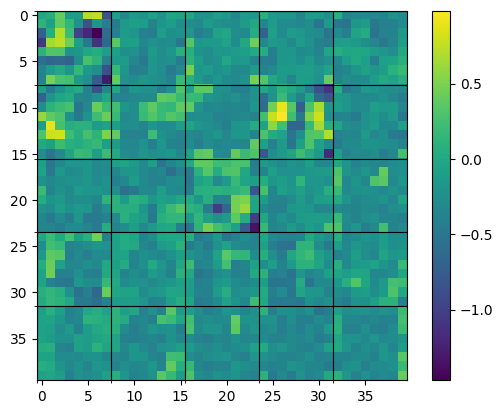

Layer no. 0 Bias:


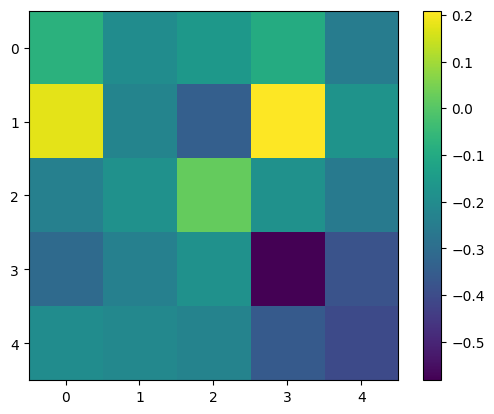

Layer no. 1 Weight:


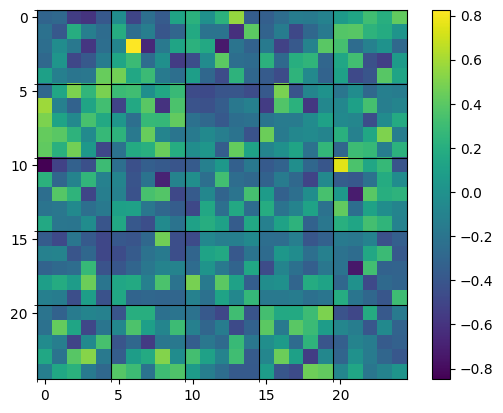

Layer no. 1 Bias:


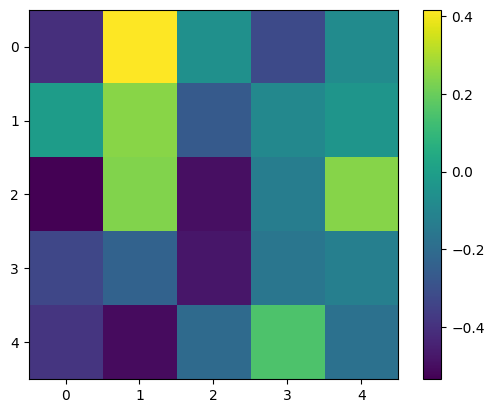

Layer no. 2 Weight:


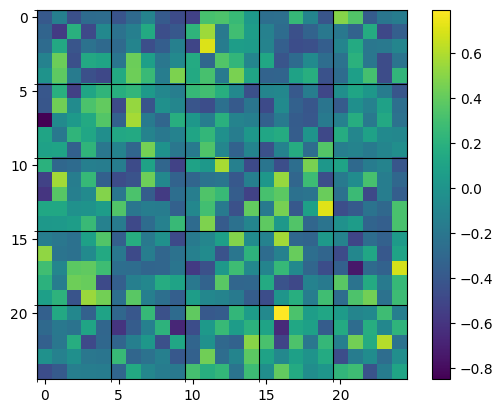

Layer no. 2 Bias:


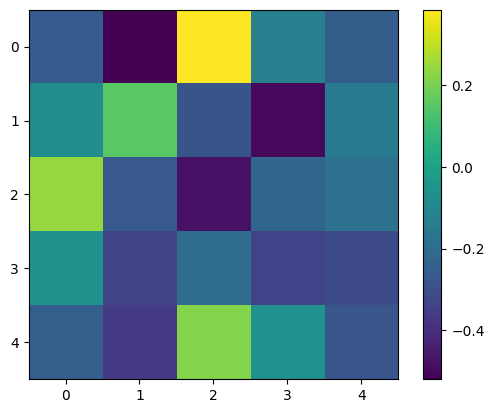

Layer no. 3 Weight:


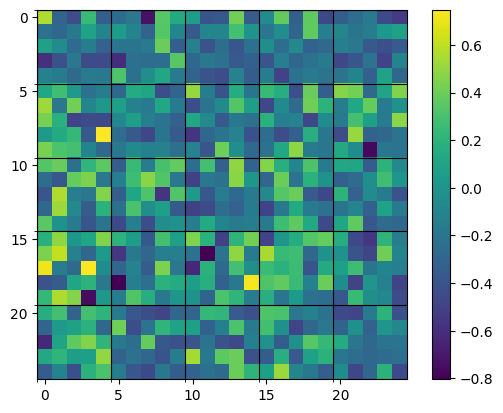

Layer no. 3 Bias:


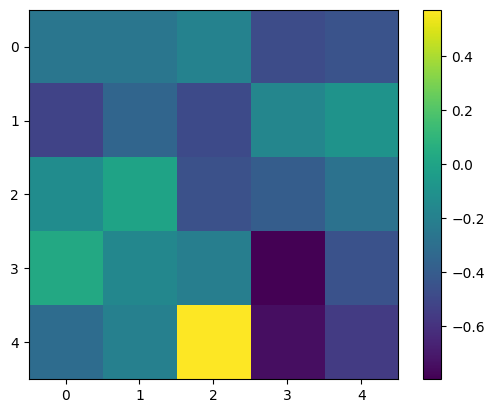

Layer no. 4 Weight:


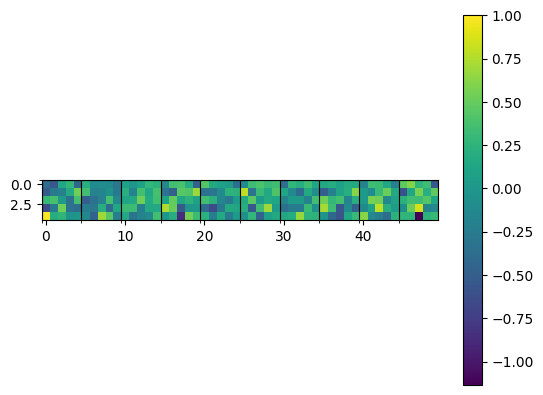

Layer no. 4 Bias:


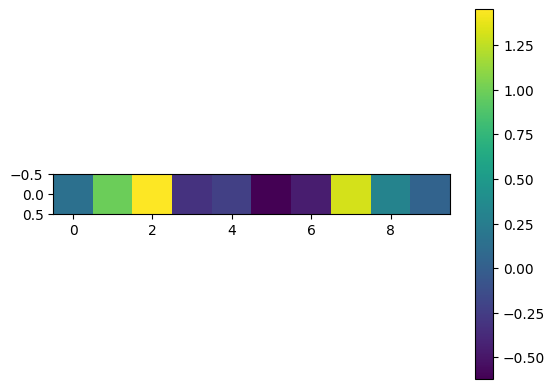

In [ ]:
#@title # **To visualize the weights and biases of the model**

print_matrices = False #@param {type:"boolean"}
CONFIG['print_matrices'] = print_matrices
def transform_weights_to_gridformat(p_n,currlayerNeurons,nextlayerNeurons,isImage=True):
  '''
  if not an image and input_layer:
    p_n = shape:(num_neurons_innextlayer,num_neurons_incurrentlayer**2)
  else:
    p_n = shape:(num_neurons_innextlayer**2,num_neurons_incurrentlayer**2)

  '''
  p_ext=[]
  all_ps = []
  # np.vstack((p_n,np.zeros(p_n.shape[-1]))
  for q,p in enumerate(p_n):
    if q%(nextlayerNeurons)==0:
      p_ext = p.reshape(-1,currlayerNeurons)
      if nextlayerNeurons==1:
        all_ps.append(p_ext)
      continue
    p_ext = np.concatenate((p_ext,p.reshape(-1,currlayerNeurons)),axis=1)
    if q%(nextlayerNeurons)==nextlayerNeurons-1:
      all_ps.append(p_ext)
  return np.concatenate(all_ps,axis=0)


def transform_biases_to_gridformat(p_n,nextlayerNeurons):
  '''
  p_n = shape:(num_neurons_innextlayer**2,)
  '''
  return p_n.reshape(-1,nextlayerNeurons)

def makeGridLines(currlayerNeurons,nextlayerNeurons,isOut = False,isImage=True):
  x = list(range(nextlayerNeurons*currlayerNeurons))

  if isOut or not isImage:
    y = list(range(currlayerNeurons))
    # currlayerNeurons=1
  else:
    y = list(range(nextlayerNeurons*currlayerNeurons))
  xmts = [x_-0.5 for x_ in x if x_%currlayerNeurons==0]
  if not isOut and not isImage:
    ymts = [y_-0.5 for y_ in y if y_%1==0]
  else:
    ymts = [y_-0.5 for y_ in y if y_%currlayerNeurons==0]
  plt.xticks(ticks = xmts,labels=['']*len(xmts),minor=True)
  plt.yticks(ticks = ymts,labels=['']*len(ymts),minor=True)
  plt.grid(which='minor',color='black')

grid_format = True #@param {type:"boolean"}
CONFIG['grid_format'] = grid_format
if print_matrices:
  print('grid_format = ',grid_format,file=open('/content/Report/misc/weights_and_biases.txt','w'))
if grid_format==False:
  is_bias=False
  layer_no = 0
  for p in model.parameters():
    p_n = p.cpu().detach().numpy()
    if is_bias:
      print(f'Layer no. {layer_no} Bias:',file=open('/content/Report/misc/weights_and_biases.txt','a'))
      print(f'Layer no. {layer_no} Bias:')
      # print(p_n,file=open('/content/Report/misc/weights_and_biases.txt','a'))
    else:
      print(f'Layer no. {layer_no} Weight:',file=open('/content/Report/misc/weights_and_biases.txt','a'))
      print(f'Layer no. {layer_no} Weight:')
    if print_matrices:
      print(p_n,file=open('/content/Report/misc/weights_and_biases.txt','a'))
      print(p_n)

    if is_bias:
      plt.matshow(p_n.reshape(1,-1),cmap='viridis')

    else:
      plt.matshow(p_n,cmap='viridis')
    plt.colorbar()
    if is_bias:
      print('<file name : weights_and_biases_layer_'+str(layer_no)+'.png>',file=open('/content/Report/misc/weights_and_biases.txt','a'))
      plt.savefig(f'/content/Report/images/weights_and_biases_layer_{layer_no}.png')
      plt.show()
      plt.close()
    if is_bias:
      is_bias=False
      layer_no+=1
    else:
      is_bias=True

# below will make it into what the neuron is looking at mode
else:
  # print()
  if len(dataset.data.shape)==3 and not ((dataset.data.shape[0])==1 or (dataset.data.shape[1])==1 or (dataset.data.shape[2])==1):
    isanimage = True
    inp_hid_out_dims = [int(input_dims**(0.5))] + hidden_dims + [output_dims]
  else:
    isanimage = False
    inp_hid_out_dims = [input_dims] + hidden_dims + [output_dims]

  is_bias=False
  layer_no = 0
  for q,p in enumerate(model.parameters()):
    p_n = p.cpu().detach().numpy()

    if is_bias:
      print(f'Layer no. {layer_no} Bias:',file=open('/content/Report/misc/weights_and_biases.txt','a'))

      print(f'Layer no. {layer_no} Bias:')
      p_n = p_n.reshape(-1,inp_hid_out_dims[layer_no+1])
      if print_matrices:
        print(p_n,file=open('/content/Report/misc/weights_and_biases.txt','a'))
        print(p_n)

      plt.imshow(p_n,cmap='viridis')


    else:
      print(f'Layer no. {layer_no} Weight:',file=open('/content/Report/misc/weights_and_biases.txt','a'))

      print(f'Layer no. {layer_no} Weight:')
      # if layer_no<len(inp_hid_out_dims)-1:
      p_n = transform_weights_to_gridformat(p_n,inp_hid_out_dims[layer_no],inp_hid_out_dims[layer_no+1],isImage=isanimage)
      # else:
      #   p_n = transform_biases_to_gridformat(p_n,inp_hid_out_dims[layer_no+1])
      if print_matrices:
        print(p_n,file=open('/content/Report/misc/weights_and_biases.txt','a'))
        print(p_n)

      plt.imshow(p_n,cmap='viridis')
      if layer_no == len(inp_hid_out_dims)-2:
        makeGridLines(inp_hid_out_dims[layer_no],inp_hid_out_dims[layer_no+1],isOut=True,isImage=isanimage)
      else:
        makeGridLines(inp_hid_out_dims[layer_no],inp_hid_out_dims[layer_no+1],isOut=False,isImage=isanimage)
      # print(inp_hid_out_dims[layer_no],,file=open('/content/Report/misc/weights_and_biases.txt','a'))
      # else:
      #   plt.imshow(p_n,cmap='viridis')
    isanimage=True
    plt.colorbar()
    if is_bias:
      print('<file name : wnb_biases_layer_'+str(layer_no)+'.png>',file=open('/content/Report/misc/weights_and_biases.txt','a'))
      plt.savefig(f'/content/Report/images/wnb_biases_layer_'+str(layer_no)+'.png')
      plt.show()
      plt.close()
      is_bias=False
      layer_no+=1
    else:
      print('<file name : wnb_weights_layer_'+str(layer_no)+'.png>',file=open('/content/Report/misc/weights_and_biases.txt','a'))
      plt.savefig(f'/content/Report/images/wnb_weights_layer_'+str(layer_no)+'.png')

      plt.show()
      plt.close()
      is_bias=True


In [ ]:
#@title # **Making the gifs related to the weights' and biases' evolution**
#@markdown **Note:** GIFs will not be made if should_record_weights was set to False

how_many_points_to_skip = 2 #@param {type:"number"}
CONFIG['how_many_points_to_skip'] = how_many_points_to_skip
#@markdown **Note:** a small number will take more time to execute. Change the number and press `Shift+Enter` to remake the gifs.
fps = 1 #@param {type:"number"}
CONFIG['fps'] = fps

print('How many points skipped between frames = ',how_many_points_to_skip,file=open('/content/Report/misc/gif_making.txt','w'))
print('fps = ',fps,file=open('/content/Report/misc/gif_making.txt','a'))
# print('How many points skipped between frames = ',how_many_points_to_skip)
# print('fps = ',fps)


def make_anim_fast(title,ind):
  # Generate example data
  # matrix_list = [torch.rand(10, 10) for _ in range(50)]  # Replace with your actual list of matrices
  matrix_list = [m[ind] for m in model.past_weights]
  # for m in matrix_list:
  #   print(m.shape)

  # Parameters for saving the animation
  h,w = matrix_list[0].shape
  print('height of the parameter matrix = ',h,file=open('/content/Report/misc/gif_making.txt','a'))
  print('width of the parameter matrix = ',w,file=open('/content/Report/misc/gif_making.txt','a'))
  print('height of the parameter matrix = ',h)
  print('width of the parameter matrix = ',w)
  frame_height, frame_width = matrix_list[0].shape
  scale_factor = max(40,int(1000/(h*w)))
  # scale_factor = 40  # Scale up the matrix to make it more visible

  min_value = min(np.min(matrix) for matrix in matrix_list)
  max_value = max(np.max(matrix) for matrix in matrix_list)
  to_pad = 100
  width_cbar = 40
  height_cbar=40

  # Function to create a color bar
  def create_color_bar(height, width=60):
      color_bar = np.linspace(0, 255, height).astype(np.uint8)
      color_bar = np.tile(color_bar[:, None], (1, width))  # Repeat horizontally
      color_bar_rgb = cv2.applyColorMap(color_bar, cv2.COLORMAP_VIRIDIS)
      return color_bar_rgb

  def create_color_bar_with_labels(height, width=40, min_val=min_value, max_val=max_value, num_ticks=5):
      # Create a blank color bar
      color_bar = np.linspace(0, 255, height).astype(np.uint8)
      color_bar = np.tile(color_bar[:, None], (1, width))  # Repeat horizontally
      color_bar_rgb = cv2.applyColorMap(color_bar, cv2.COLORMAP_VIRIDIS)
      color_bar_rgb = np.pad(color_bar_rgb,((to_pad, to_pad),(to_pad,to_pad),(0,0)),'constant',constant_values=255)

      # Add numeric labels to the color bar
      tick_positions = np.linspace(0, height - 1, num_ticks).astype(int)
      tick_values = np.linspace(min_val, max_val, num_ticks)

      for i, (pos, val) in enumerate(zip(tick_positions, tick_values)):
          label = f"{val:.2f}"
          if label[0]!='-':
            label = '+'+label
          # Place the label on the color bar image
          font_scale = 1
          thickness = 5
          text_size = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)[0]
          text_x = width - text_size[0] + 50  # Align text to the right
          text_y = pos + int(text_size[1] / 2)
          cv2.putText(color_bar_rgb, label, (0, text_y+to_pad), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), thickness, cv2.LINE_AA)

      return color_bar_rgb

  def create_horizontal_color_bar_with_labels(width,height=40, min_val=min_value, max_val=max_value, num_ticks=5):
      # Create a blank color bar
      color_bar = np.linspace(0, 255, width).astype(np.uint8)
      color_bar = np.tile(color_bar[:], (height, 1))  # Repeat horizontally
      color_bar_rgb = cv2.applyColorMap(color_bar, cv2.COLORMAP_VIRIDIS)
      color_bar_rgb = np.pad(color_bar_rgb,((to_pad, to_pad),(to_pad,to_pad),(0,0)),'constant',constant_values=255)

      # Add numeric labels to the color bar
      tick_positions = np.linspace(width-1, 0, num_ticks).astype(int)
      tick_values = np.linspace(min_val, max_val, num_ticks)

      for i, (pos, val) in enumerate(zip(tick_positions, tick_values)):
          label = f"{val:.2f}"
          if label[0]!='-':
            label = '+'+label
          # Place the label on the color bar image
          thickness = 5
          font_scale = 1
          text_size = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)[0]
          if text_size[0]*6>=width:
            thickness = 1
            font_scale = 0.4
          text_size = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)[0]
          text_y = to_pad - int(text_size[1]) # Align text to the right
          text_x = pos - int(text_size[0] / 2)
          cv2.putText(color_bar_rgb, label, (text_x+to_pad, text_y), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), thickness, cv2.LINE_AA)

          text_size = cv2.getTextSize('|', cv2.FONT_HERSHEY_SIMPLEX, 0.3, thickness)[0]
          text_y = to_pad - int(text_size[1]) # Align text to the right
          text_x = pos - int(text_size[0] / 2)
          cv2.putText(color_bar_rgb, '|', (text_x+to_pad, text_y), cv2.FONT_HERSHEY_SIMPLEX, 0.2, (0, 0, 0), thickness, cv2.LINE_AA)
      return color_bar_rgb


  # Create a video writer object using OpenCV
  from_file = f"/content/Report/movies/{title}_fast.mp4"
  # out = cv2.VideoWriter(from_file, cv2.VideoWriter_fourcc(*'XVID'), fps,
  #                       (frame_width * scale_factor + width_cbar + 4*to_pad, frame_height * scale_factor + 2*to_pad))  # Extra width for the color bar # 20 for padding

  out = cv2.VideoWriter(from_file, cv2.VideoWriter_fourcc(*'XVID'), fps,
                        (frame_width * scale_factor + 2*to_pad, frame_height * scale_factor + height_cbar+4*to_pad))  # Extra width for the color bar # 20 for padding

  # Create a color bar
  color_bar_padded = create_color_bar_with_labels(frame_height * scale_factor)
  color_bar_horizontal_padded = create_horizontal_color_bar_with_labels(frame_width * scale_factor)

  # Iterate through the list of matrices
  for i,matrix in enumerate(matrix_list):
      if i%how_many_points_to_skip!=0 and i!=len(matrix_list)-1:
        continue
      # Convert the tensor to a numpy array
      frame = matrix

      # Scale up the matrix for better visualization
      frame_scaled = cv2.resize(frame, (frame_width * scale_factor, frame_height * scale_factor), interpolation=cv2.INTER_NEAREST)

      # Normalize to 0-255 range and convert to 8-bit grayscale
      frame_normalized = cv2.normalize(frame_scaled, None, 0, 255, cv2.NORM_MINMAX)
      frame_uint8 = frame_normalized.astype(np.uint8)

      # Convert grayscale to RGB using a colormap
      frame_rgb = cv2.applyColorMap(frame_uint8, cv2.COLORMAP_VIRIDIS)
      frame_rgb_padded = np.pad(frame_rgb, ((to_pad, to_pad),(to_pad,to_pad),(0,0)), 'constant', constant_values=255)
      font_scale=2
      thickness=10
      text_size = cv2.getTextSize(str(i), cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)[0]
      font_scale = font_scale*((to_pad-20))/(text_size[1])
      text_size = cv2.getTextSize(str(i), cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)[0]

      # Combine the frame with the color bar
      # num_X = to_pad - int(text_size[0])-5
      # num_Y = int(len(frame_rgb_padded[1])/2)-int(text_size[1]/2)
      num_X = 5#int((to_pad/2) - (text_size[0]/2))
      num_Y = text_size[1]+5#int((to_pad/2) - (text_size[1]/2))
      cv2.putText(frame_rgb_padded, str(i), (num_X,num_Y), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), thickness, cv2.LINE_AA)

      # font = cv2.FONT_HERSHEY_SIMPLEX
      # text = "Hello Joseph!!"

      # # get boundary of this text
      # textsize = cv2.getTextSize(title, font, font_scale, thickness)[0]

      # get coords based on boundary
      # textX = (frame_rgb_padded.shape[1] - textsize[0]) / 2
      # cv2.putText(frame_rgb_padded, title, (textX, len(frame_rgb_padded)-int(to_pad/1.5)), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), thickness, cv2.LINE_AA)

      # combined_frame = np.hstack((frame_rgb_padded, color_bar_padded))
      # print(frame_rgb_padded.shape)
      # print(color_bar_horizontal_padded.shape)
      combined_frame = np.vstack((frame_rgb_padded,color_bar_horizontal_padded))
      # print('shape ', combined_frame.shape)
      # print('dimentions ',(frame_width * scale_factor + width_cbar + 4*to_pad, frame_height * scale_factor + 2*to_pad))
      # Write the frame to the video
      # print(combined_frame)
      out.write(combined_frame)

  # Release the video writer
  out.release()

  # Convert the MP4 video to a GIF using PIL (optional, for better visualization)
  # display(Video('animation_with_colorbar.mp4'))
  # from_file = "animation_with_colorbar.mp4"
  to_file = f"/content/Report/movies/{title}_fast.gif"
  f=f"fps={fps},scale=600:-1:flags=lanczos"
  !echo "$from_file"
  !echo "$to_file"
  !ffmpeg -hide_banner -loglevel error -y -i  "$from_file" -vf $f -c:v gif "$to_file"

# Display the GIF
def show_anim_fast(title):
  display(Image(filename=f'/content/Report/movies/{title}_fast.gif'))


is_bias=False
layer_no = 0
p_no=0
titles=[]
if len(model.past_weights)!=0:
  for p in tqdm([pp for pp in model.parameters()]):
    if is_bias:
      print(f'Layer no. {layer_no} Bias:',file=open('/content/Report/misc/gif_making.txt','a'))
      print(f'Layer no. {layer_no} Bias:')
      make_anim_fast(f'Layer_no_{layer_no}_Bias',p_no)
      titles.append(f'Layer_no_{layer_no}_Bias')
      print('<file name : '+f"/content/Report/movies/{titles[-1]}_fast.mp4",file=open('/content/Report/misc/gif_making.txt','a'))
      print('<file name : '+f"/content/Report/movies/{titles[-1]}_fast.gif",file=open('/content/Report/misc/gif_making.txt','a'))
    else:
      print(f'Layer no. {layer_no} Weight:',file=open('/content/Report/misc/gif_making.txt','a'))
      print(f'Layer no. {layer_no} Weight:')

      make_anim_fast(f'Layer_no_{layer_no}_Weight',p_no)
      titles.append(f'Layer_no_{layer_no}_Weight')
      print('<file name : '+f"/content/Report/movies/{titles[-1]}_fast.mp4",file=open('/content/Report/misc/gif_making.txt','a'))
      print('<file name : '+f"/content/Report/movies/{titles[-1]}_fast.gif",file=open('/content/Report/misc/gif_making.txt','a'))
    if is_bias:
      is_bias=False
      layer_no+=1
    else:
      is_bias=True
    p_no+=1


In [ ]:
#@title # **Visualizing the parameters**
if len(model.past_weights)!=0:
  for t in titles:
    print(t)
    show_anim_fast(t)

Layer_no_0_Weight


FileNotFoundError: [Errno 2] No such file or directory: '/content/Report/movies/Layer_no_0_Weight_fast.gif'

In [ ]:
# @title # **Making the Report.zip file**
print(CONFIG,file=open('/content/Report/misc/CONFIG.txt','w'))
print(FINAL_SAVE,file = open('/content/Report/misc/FINAL_SAVE.txt','w'))
torch.save(model,'/content/Report/models/model.pt')
torch.save(optimizer,'/content/Report/models/optimizer.pt')
print('''# **InteractiveNNTeacher README file**
This file describes the ins and outs of how NN Teacher works and how one can read the report

1. The Report folder contains 4 folders namely images, misc, models and movies.
2. The misc subfolder must be read first to make heads and tails of the other info provided.
3. movies subfolder has both .gif and .mp4 files either of which can be used, as both display the same information. This folder would be empty is the parameter `should_record_weights` was set to False.

## The images and movies subfolders

The files stored here are refered to via the files in misc with the indication of <file name : ... > tag.

## The misc subfolder

The misc subfolder contains 6 .txt files and 1 .npy file. The following talks about the purpose of each of those files.

1. **CONFIG.txt** deals with all the configurational variables, indicating things the user could have changes and chose for the run
2. **FINAL_SAVE.txt** deals with all the variables generated after training of the model
3. **about_data.txt** describes the dataset and various properties of the dataset and targetset that the user could be interested in. It further refers to an image which shows visually a few samples of the data
4. **gif_making.txt** is useful for refering to which movie file in the movies subfolder corresponds to which parameter of the model. The file refers to these movie by file name as well for helping the user navigate through the movies subfolder
5. **permut.npy** gives the order of the entries after shuffling the dataset
6. **sample_intermediate.txt** shows a sample input being processed by visualizing the output of each layer. The file also refers to a series of images in the images subfolder which may be refered for a deeper understanding of what the matrix included in the txt file looks like
7. **weights_and_biases.txt** allows the user to visualize the final weights in a format they had chosen throught the variable `grid_format`. The user can refer to the refered images in the images sub folder for a better understanding of the neurons involved in each layer.

## The models subfolder

To use the model in the future, user is provided with .pt files of the model and optimizer in the models sub folder. A simple torch.load("/content/Report/models/model.pt") will allow the user the retrieve the model back in this colab interface for future use. The user is advised to download the model.pt after the run is over so that its not erased permanently.

''',file=open('/content/Report/README.md','w'))
# Create 'path\to\zip_file.zip'
zip_name = '/content/Report'
directory_name = '/content/Report/'
print('Report.zip made at : ' , shutil.make_archive(zip_name, 'zip', directory_name))
